# Aviation AI — Smart Airport Assistant

Live King Khalid International Airport (KKIA) flight lookup with LiquidAI/LFM2.5-1.2B-Instruct tool calling.

This notebook demonstrates university AI Agent lab concepts with real airport data (no invented flights).

## 1. Install libraries

Install packages needed for flight retrieval, validation, the local LLM, evaluation, and charts.

ملاحظة: تم تطبيق مفهوم إعداد البيئة (Environment Setup) من المعمل الثاني (Lab 2).

In [1]:
%pip install -q requests pydantic torch transformers accelerate pandas matplotlib


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: /Users/janaalgurashi/Desktop/Aviation AI/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Retrieve live airport data

Fetch the public KKIA JSON feed with retries. API failures are separate from "flight not found".

ملاحظة: تم تطبيق مفهومي إعادة المحاولة (Retry Logic) والتعامل مع الفشل (Error Handling) من المعمل الثاني (Lab 2).

In [2]:
import ast
import asyncio
import json
import re
import time
from dataclasses import dataclass, field
from datetime import datetime, timezone
from threading import Thread
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import requests
import torch
from pydantic import BaseModel, Field, ValidationError, field_validator
from transformers import AutoModelForCausalLM, AutoTokenizer, TextIteratorStreamer

FLIGHTS_API = "https://www.kkia.sa/api/flightsInformation"
PAGE_URL = "https://www.kkia.sa/en/Flights/Departures-and-Arrivals"
MODEL_ID = "LiquidAI/LFM2.5-1.2B-Instruct"

class FlightAPIError(Exception):
    pass

raw_flights = []
last_refresh_utc = None
lookup_cache = {}
cache_hits = 0
cache_misses = 0
CACHE_TTL = 60.0

def refresh_flights(retries=3, delay=1.0, timeout=30):
    global raw_flights, last_refresh_utc, lookup_cache
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(
                FLIGHTS_API,
                headers={"User-Agent": "AviationAI-Notebook/1.0", "Accept": "application/json"},
                timeout=timeout,
            )
            r.raise_for_status()
            payload = r.json()
            if not isinstance(payload, list):
                raise FlightAPIError(f"Unexpected JSON type: {type(payload).__name__}")
            raw_flights = payload
            last_refresh_utc = datetime.now(timezone.utc).isoformat()
            lookup_cache = {}
            print(f"Refresh OK (attempt {attempt}): {len(raw_flights)} flights @ {last_refresh_utc}")
            return len(raw_flights)
        except (requests.Timeout, requests.ConnectionError, requests.HTTPError, ValueError, FlightAPIError) as e:
            last_error = e
            print(f"Attempt {attempt} failed: {e}")
            if attempt < retries:
                time.sleep(delay)
    raise FlightAPIError(f"Refresh failed after {retries} attempts: {last_error}")

n = refresh_flights()
print("Source:", PAGE_URL)
print("Flights loaded:", n)

Refresh OK (attempt 1): 244 flights @ 2026-11-10T10:43:22.876911+00:00
Source: https://www.kkia.sa/en/Flights/Departures-and-Arrivals
Flights loaded: 244


## 3. Simple flight lookup

Parse live rows and search by flight number / optional date. Missing fields stay unavailable — they are never invented.

ملاحظة: تم تطبيق مفهوم استرجاع البيانات الحية (Live Data Retrieval) مع التحقق من القيم المفقودة.

In [3]:
def normalize_flight_number(value: str) -> str:
    return re.sub(r"[\s\-_]+", "", (value or "").upper())

def parse_flight(item: dict) -> dict:
    extra = (item.get("flightExtraData") or [None])[0] or {}
    airline = item.get("airline") or {}
    code = (extra.get("airlineCode") or airline.get("code") or "").strip()
    number = str(item.get("number") or "").strip()
    suffix = str(item.get("flightNumberSuffix") or "").strip()
    dep, arr = item.get("departureAirport") or {}, item.get("arrivalAirport") or {}

    def place(airport):
        label = (airport.get("description") or airport.get("name") or "").strip()
        c = (airport.get("code") or "").strip()
        return f"{label} ({c})" if label and c else (label or c or None)

    status = extra.get("flightStatus") or extra.get("flightState") or item.get("remark")
    gate = item.get("passengerGate") or extra.get("passengerGate")
    terminal = item.get("aircraftTerminal") or extra.get("publicTerminal")
    return {
        "flight_number": f"{code}{number}{suffix}" or None,
        "airline": extra.get("airlineDescription") or airline.get("description"),
        "direction": item.get("departureOrArrival"),
        "origin": place(dep),
        "destination": place(arr),
        "scheduled_time": item.get("scheduled"),
        "terminal": terminal,
        "gate": gate,
        "flight_status": status,
    }

def show(v):
    return v if v not in (None, "") else "<not available>"

def get_flight_info(flight_number: str, flight_date: str | None = None, use_cache: bool = True):
    global cache_hits, cache_misses
    needle = normalize_flight_number(flight_number)
    date_filter = flight_date.strip() if flight_date else None
    key = (needle, date_filter)
    if use_cache and key in lookup_cache:
        ts, cached = lookup_cache[key]
        if time.time() - ts <= CACHE_TTL:
            cache_hits += 1
            out = dict(cached)
            out["from_cache"] = True
            return out
    cache_misses += 1
    matches = []
    for item in raw_flights:
        flight = parse_flight(item)
        if not flight["flight_number"]:
            continue
        if normalize_flight_number(flight["flight_number"]) != needle:
            continue
        if date_filter and not str(flight["scheduled_time"] or "").startswith(date_filter):
            continue
        row = {k: show(v) for k, v in flight.items()}
        # Per-flight notes (fixed shared-list bug)
        notes = []
        if row["flight_status"] == "<not available>":
            notes.append("Flight status is currently unavailable.")
        if row["gate"] == "<not available>":
            notes.append("Gate is currently unavailable.")
        row["notes"] = notes
        matches.append(row)
    result = {
        "found": bool(matches),
        "message": (
            f"Found {len(matches)} matching flight(s)."
            if matches else "This flight is unavailable in the current airport feed."
        ),
        "flights": matches,
        "retrieved_at_utc": last_refresh_utc,
        "from_cache": False,
    }
    if needle:
        lookup_cache[key] = (time.time(), result)
    return result

sample = parse_flight(raw_flights[0])
sample_number = sample["flight_number"]
sample_date = (sample["scheduled_time"] or "")[:10] or None
demo = get_flight_info(sample_number, sample_date)
print("Sample:", sample_number, sample_date)
print(demo["message"])
if demo["flights"]:
    f = demo["flights"][0]
    print(f"{f['flight_number']} | {f['direction']} | terminal={f['terminal']} | gate={f['gate']} | status={f['flight_status']}")

Sample: XY790 2026-11-12
Found 1 matching flight(s).
XY790 | Arrival | terminal=T1 | gate=<not available> | status=<not available>


## 4. Load the LLM

Load LiquidAI/LFM2.5-1.2B-Instruct. Prefer CUDA (Colab), then MPS (Mac), else CPU.

ملاحظة: تم تطبيق مفهوم تحميل النموذج اللغوي (Model Loading) من المعمل الأول (Lab 1).

In [4]:
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
dtype = torch.bfloat16 if device == "cuda" else (torch.float16 if device == "mps" else torch.float32)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype)
model.to(device)
model.eval()

def count_tokens(text: str) -> int:
    return len(tokenizer.encode(text))

def generate(messages, max_new_tokens=256):
    inputs = tokenizer.apply_chat_template(messages, add_generation_prompt=True, return_dict=True, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.inference_mode():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, repetition_penalty=1.05, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=False)

print(f"Loaded {MODEL_ID} on {device}")

W1110 13:43:24.960000 59206 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded LiquidAI/LFM2.5-1.2B-Instruct on mps


## 5. Lab 1 — Tokenization and cost analysis

Tokenize representative airport questions with the LiquidAI tokenizer and compare token counts.

ملاحظة: تم تطبيق مفاهيم تقسيم النص إلى رموز (Tokenization) وتحليل استهلاك الرموز (Token Analysis) من المعمل الأول (Lab 1).

In [5]:
questions_lab1 = [
    "What is the status of flight SV1096?",
    "Which terminal is flight XY790 on 2026-11-12?",
    "What gate should I go to for my flight?",
    "هل بوابة الرحلة SV1096 جاهزة؟",
]

rows = []
for q in questions_lab1:
    ids = tokenizer.encode(q)
    rows.append({"question": q, "chars": len(q), "tokens": len(ids)})
token_df = pd.DataFrame(rows)
print(token_df.to_string(index=False))
print("\nMore tokens usually means more compute/memory for local inference.")
print("Estimated commercial API cost example (NOT current live prices; for teaching only):")
# Teaching estimate only — values are illustrative, not guaranteed market prices.
ILLUSTRATIVE_USD_PER_1M = {"input": 0.50, "output": 1.50}
for _, r in token_df.iterrows():
    est = r["tokens"] * ILLUSTRATIVE_USD_PER_1M["input"] / 1_000_000
    print(f"- {r['tokens']} input tokens ≈ ${est:.6f} (illustrative API estimate; local GPU has no per-token API bill)")

                                     question  chars  tokens
         What is the status of flight SV1096?     36      11
Which terminal is flight XY790 on 2026-11-12?     45      17
      What gate should I go to for my flight?     39      11
                هل بوابة الرحلة SV1096 جاهزة؟     29      15

More tokens usually means more compute/memory for local inference.
Estimated commercial API cost example (NOT current live prices; for teaching only):
- 11 input tokens ≈ $0.000005 (illustrative API estimate; local GPU has no per-token API bill)
- 17 input tokens ≈ $0.000008 (illustrative API estimate; local GPU has no per-token API bill)
- 11 input tokens ≈ $0.000005 (illustrative API estimate; local GPU has no per-token API bill)
- 15 input tokens ≈ $0.000008 (illustrative API estimate; local GPU has no per-token API bill)


## 6. Tool Schema and Pydantic validation

Define the `get_flight_info` tool and validate arguments before execution.

ملاحظة: تم تطبيق مفهومي تعريف الأدوات (Tool Schema) والتحقق من المدخلات (Pydantic Validation) من المعمل الثالث (Lab 3).

In [6]:
TOOL_SCHEMA = {
    "name": "get_flight_info",
    "description": "Look up live KKIA flight info by flight number. Use for status, gate, terminal, time, arrival, or departure. Do not invent data.",
    "parameters": {
        "type": "object",
        "properties": {
            "flight_number": {"type": "string", "description": "e.g. SV1096"},
            "flight_date": {"type": "string", "description": "Optional YYYY-MM-DD"},
        },
        "required": ["flight_number"],
    },
}

class GetFlightInfoArgs(BaseModel):
    flight_number: str = Field(min_length=2)
    flight_date: str | None = None

    @field_validator("flight_number")
    @classmethod
    def clean_number(cls, v: str) -> str:
        if v is None or not str(v).strip():
            raise ValueError("flight_number is required")
        cleaned = re.sub(r"[\s\-_]+", "", str(v).strip().upper())
        if not re.fullmatch(r"[A-Z0-9]{2,3}\d{1,4}[A-Z]?", cleaned):
            raise ValueError("flight_number must look like SV1096 or XY330B")
        return cleaned

    @field_validator("flight_date")
    @classmethod
    def clean_date(cls, v: str | None) -> str | None:
        if v is None or not str(v).strip():
            return None
        v = str(v).strip()
        if not re.fullmatch(r"\d{4}-\d{2}-\d{2}", v):
            raise ValueError("flight_date must be YYYY-MM-DD")
        return v

print("Tool:", TOOL_SCHEMA["name"], "| required:", TOOL_SCHEMA["parameters"]["required"])
print("OK:", GetFlightInfoArgs(flight_number="sv 1096", flight_date="2026-11-11"))
try:
    GetFlightInfoArgs(flight_number="", flight_date="11-11-2026")
except ValidationError as e:
    print("Invalid args caught:", e.errors()[0]["msg"])

Tool: get_flight_info | required: ['flight_number']
OK: flight_number='SV1096' flight_date='2026-11-11'
Invalid args caught: String should have at least 2 characters


## 7. Tool Registry

Map the tool name to the real Python lookup function only (no arbitrary execution).

ملاحظة: تم تطبيق مفهوم تسجيل الأدوات (Tool Registry) من المعمل الثالث (Lab 3).

In [7]:
TOOL_REGISTRY = {
    "get_flight_info": lambda flight_number, flight_date=None: get_flight_info(flight_number, flight_date)
}
print("Registered:", list(TOOL_REGISTRY.keys()))

Registered: ['get_flight_info']


## 8. LLM Tool Calling

Two-call pattern: model selects a tool → Python validates/executes → model answers from verified results.

ملاحظة: تم تطبيق مفهوم استدعاء الأدوات (Tool Calling) من المعمل الثالث (Lab 3).

In [8]:
SYSTEM_PROMPT = f'''You are Aviation AI for King Khalid International Airport (Riyadh).
If the user message contains a flight number made of letters+digits (examples: XY790, SV1096, ZZ9999), you MUST call get_flight_info with that number.
Tool call format:
<|tool_call_start|>[get_flight_info(flight_number="ZZ9999", flight_date="2099-01-01")]<|tool_call_end|>
Include flight_date only when the user gave YYYY-MM-DD.
If the user message has NO flight number at all, do NOT call a tool. Reply exactly:
Please share your flight number (like SV1096) and I will look up the live information.
Never invent flight details. Keep status, gate, terminal, and scheduled time separate.
If flight_status is <not available>, say exactly: Flight status is currently unavailable.
If found is false, say the flight is unavailable in the current airport feed.
List of tools: {json.dumps([TOOL_SCHEMA])}'''

TOOL_CALL_RE = re.compile(r"<\|tool_call_start\|>(.*?)<\|tool_call_end\|>", re.S)

def parse_tool_calls(text: str):
    calls, errors = [], []
    matches = list(TOOL_CALL_RE.finditer(text or ""))
    for m in matches:
        body = m.group(1).strip()
        if not body:
            errors.append("Empty tool call")
            continue
        if not body.startswith("["):
            body = f"[{body}]"
        try:
            node = ast.parse(body, mode="eval").body
            call = node.elts[0]
            if call.args:
                errors.append("Positional args are not allowed")
                continue
            args = {kw.arg: ast.literal_eval(kw.value) for kw in call.keywords if kw.arg}
            calls.append({"name": call.func.id, "arguments": args})
        except Exception as e:
            errors.append(f"Malformed tool call: {e}")
    return {"calls": calls, "errors": errors}

def execute_tool(name: str, arguments: dict):
    if name not in TOOL_REGISTRY:
        return {"error": f"Unknown tool: {name}", "available_tools": list(TOOL_REGISTRY.keys())}
    if name != "get_flight_info":
        return {"error": f"Tool '{name}' is not enabled"}
    try:
        args = GetFlightInfoArgs.model_validate(arguments or {})
    except ValidationError as e:
        return {"error": "Invalid tool arguments", "details": e.errors()}
    return TOOL_REGISTRY[name](args.flight_number, args.flight_date)

def clean(text: str) -> str:
    for t in ["<|tool_call_start|>", "<|tool_call_end|>", "<|im_end|>", "<|im_start|>"]:
        text = text.replace(t, "")
    return text.strip()

# Lab 7 tracing
trace_events = []
def observe(fn):
    def wrap(*a, **k):
        trace_events.append(f"trace_started:{fn.__name__}")
        out = fn(*a, **k)
        trace_events.append(f"trace_completed:{fn.__name__}")
        return out
    return wrap

# Lab 6 memory
@dataclass
class Memory:
    messages: list = field(default_factory=list)
    current_flight_number: str | None = None
    current_flight_date: str | None = None
    last_facts: dict = field(default_factory=dict)
    window_size: int = 6

    def resolve(self, question: str) -> str:
        m = re.search(r"\b([A-Z]{2,3}\s?-?\s?\d{1,4}[A-Z]?)\b", question, re.I)
        d = re.search(r"\b(\d{4}-\d{2}-\d{2})\b", question)
        if m:
            self.current_flight_number = normalize_flight_number(m.group(1))
        if d:
            self.current_flight_date = d.group(1)
        follow = bool(re.search(r"\b(its|it|that flight|the flight)\b", question, re.I)) or (
            self.current_flight_number and not m and re.search(r"\b(gate|terminal|status|delayed)\b", question, re.I)
        )
        if follow and self.current_flight_number and not m:
            extra = f" (flight {self.current_flight_number}"
            if self.current_flight_date:
                extra += f" on {self.current_flight_date}"
            extra += ")"
            return question + extra
        return question

    def update_from_tool(self, result: dict):
        if not result.get("found") or not result.get("flights"):
            return
        f = result["flights"][0]
        self.current_flight_number = f.get("flight_number") or self.current_flight_number
        self.last_facts = {k: f.get(k) for k in ["terminal", "gate", "flight_status", "scheduled_time"]}
        if isinstance(f.get("scheduled_time"), str) and len(f["scheduled_time"]) >= 10:
            self.current_flight_date = f["scheduled_time"][:10]

    def fidelity_ok(self, summary: str) -> bool:
        important = [v for v in [self.current_flight_number, self.current_flight_date] if v]
        for k in ["terminal", "gate", "flight_status"]:
            v = self.last_facts.get(k)
            if v and v != "<not available>":
                important.append(str(v))
        return all(x in summary for x in important)

memory = Memory()

@observe
def ask(question: str, max_steps: int = 3, mem: Memory | None = None):
    start = time.time()
    mem = mem if mem is not None else memory
    resolved = mem.resolve(question)
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": resolved}]
    first = generate(messages)
    parsed = parse_tool_calls(first)
    calls, errors = parsed["calls"], parsed["errors"]
    out = {
        "question": question,
        "resolved": resolved,
        "used_tool": False,
        "tool_call": None,
        "retrieved": None,
        "final": None,
        "stopped_reason": None,
        "latency_s": None,
        "input_tokens": count_tokens(resolved),
        "output_tokens": count_tokens(first),
        "parse_errors": errors,
    }
    if errors and not calls:
        out["final"] = "I could not read a valid tool call. Please rephrase with a clear flight number."
        out["stopped_reason"] = "malformed_tool_call"
        out["latency_s"] = time.time() - start
        return out
    if not calls:
        out["final"] = clean(first)
        out["latency_s"] = time.time() - start
        return out

    seen = set()
    for step in range(max_steps):
        call = calls[0]
        sig = json.dumps(call, sort_keys=True)
        if sig in seen:
            out["stopped_reason"] = "loop_detected"
            out["final"] = "Stopped: repeated identical tool call detected."
            break
        seen.add(sig)
        result = execute_tool(call["name"], call.get("arguments") or {})
        out["used_tool"] = True
        out["tool_call"] = call
        out["retrieved"] = result
        if call["name"] == "get_flight_info":
            mem.update_from_tool(result)
        messages.append({"role": "assistant", "content": first})
        messages.append({"role": "tool", "name": call["name"], "content": json.dumps(result)})
        reminder = f'Passenger question: "{resolved}". Answer in one short plain sentence using ONLY the tool result. Do not invent details.'
        if result.get("error"):
            reminder += f" Tool error: {result['error']}."
        elif not result.get("found"):
            reminder += ' Reply exactly: "This flight is unavailable in the current airport feed."'
        elif "status" in resolved.lower() and result["flights"] and result["flights"][0]["flight_status"] == "<not available>":
            reminder += ' Reply exactly: "Flight status is currently unavailable."'
        messages.append({"role": "user", "content": reminder})
        first = generate(messages, max_new_tokens=160)
        out["output_tokens"] += count_tokens(first)
        parsed = parse_tool_calls(first)
        calls = parsed["calls"]
        if not calls:
            out["final"] = clean(first)
            break
    else:
        out["stopped_reason"] = "max_steps"
        out["final"] = out["final"] or f"Stopped safely after max_steps={max_steps}."
    out["latency_s"] = time.time() - start
    return out

print("Tool-calling workflow ready.")

Tool-calling workflow ready.


## 9. Lab 2 — Streaming and TTFT

Small streaming experiment with `TextIteratorStreamer`. TTFT is time until the first streamed text chunk.

ملاحظة: تم تطبيق مفاهيم إعادة المحاولة (Retry Logic)، والتخزين المؤقت (Caching)، والبث التدريجي (Streaming)، وقياس زمن الاستجابة (TTFT) من المعمل الثاني (Lab 2).

In [9]:
# Cache timing demo (lookup-only)
lookup_cache.clear()
cache_hits = cache_misses = 0
t0 = time.perf_counter(); r1 = get_flight_info(sample_number, sample_date); miss_s = time.perf_counter() - t0
t0 = time.perf_counter(); r2 = get_flight_info(sample_number, sample_date); hit_s = time.perf_counter() - t0
print(f"Cache miss: {miss_s*1000:.1f} ms | from_cache={r1['from_cache']}")
print(f"Cache hit : {hit_s*1000:.1f} ms | from_cache={r2['from_cache']}")
print(f"Hits={cache_hits} Misses={cache_misses}")

# Streaming + TTFT experiment (local generation)
stream_messages = [
    {"role": "system", "content": "You are Aviation AI. Answer briefly. Do not invent flight data."},
    {"role": "user", "content": "In one sentence, explain what a boarding gate number means at an airport."},
]
inputs = tokenizer.apply_chat_template(stream_messages, add_generation_prompt=True, return_dict=True, return_tensors="pt")
inputs = {k: v.to(device) for k, v in inputs.items()}
streamer = TextIteratorStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True)
start = time.time(); first = None; chunks = []
Thread(target=model.generate, kwargs={**inputs, "streamer": streamer, "max_new_tokens": 60, "do_sample": False, "pad_token_id": tokenizer.eos_token_id}).start()
for text in streamer:
    if first is None and text:
        first = time.time()
    chunks.append(text)
print("Streamed:", "".join(chunks).strip())
print(f"TTFT: {(first-start)*1000:.0f} ms | Total generation: {time.time()-start:.2f} s")
print("TTFT = time to first streamed token/text. Total = full generation time.")

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


Cache miss: 0.5 ms | from_cache=False
Cache hit : 0.0 ms | from_cache=True
Hits=1 Misses=1


Streamed: A boarding gate number indicates the specific gate at which passengers will be waiting to board their flights.
TTFT: 154 ms | Total generation: 0.35 s
TTFT = time to first streamed token/text. Total = full generation time.


## 10. Lab 3 — Parallel tool execution

Compare sequential vs parallel independent lookups. A labeled simulated I/O delay makes the concept visible when lookups are in-memory.

ملاحظة: تم تطبيق مفاهيم التحقق من المدخلات (Pydantic)، وتعريف الأدوات (Tool Schema)، وتسجيل الأدوات (Tool Registry)، والتنفيذ المتوازي (Parallel Tool Calls) من المعمل الثالث (Lab 3).

In [10]:
# Pick two real flight numbers from the feed
real_flights = []
for item in raw_flights:
    f = parse_flight(item)
    if f["flight_number"] and f["flight_number"] not in real_flights:
        real_flights.append(f["flight_number"])
    if len(real_flights) >= 2:
        break
reqs = [{"flight_number": real_flights[0]}, {"flight_number": real_flights[1]}]
SIM_DELAY = 0.35  # labeled simulation to demonstrate parallelism

def sequential(reqs, delay):
    t0 = time.perf_counter(); outs = []
    for r in reqs:
        time.sleep(delay)
        outs.append(get_flight_info(r["flight_number"]))
    return outs, time.perf_counter() - t0

async def parallel(reqs, delay):
    async def one(r):
        await asyncio.sleep(delay)
        return await asyncio.to_thread(get_flight_info, r["flight_number"])
    t0 = time.perf_counter()
    outs = await asyncio.gather(*(one(r) for r in reqs))
    return list(outs), time.perf_counter() - t0

seq_out, seq_t = sequential(reqs, SIM_DELAY)
par_out, par_t = await parallel(reqs, SIM_DELAY)
print("Requests:", reqs)
print(f"Sequential: {seq_t:.2f}s | Parallel: {par_t:.2f}s | Simulated I/O delay/request: {SIM_DELAY}s")
print("Note: parallel is not always faster; here delay is simulated to show the concept.")
print("Results found flags:", [o["found"] for o in seq_out], [o["found"] for o in par_out])

Requests: [{'flight_number': 'XY790'}, {'flight_number': 'XY038'}]
Sequential: 0.71s | Parallel: 0.35s | Simulated I/O delay/request: 0.35s
Note: parallel is not always faster; here delay is simulated to show the concept.
Results found flags: [True, True] [True, True]


## 11. Lab 6 — Conversation memory and fidelity gate

Track the current flight so follow-ups like "What is its terminal?" stay grounded.

ملاحظة: تم تطبيق مفاهيم إدارة سياق المحادثة (Conversation Context) والحفاظ على المعلومات المهمة (Fidelity Gate) من المعمل السادس (Lab 6).

In [11]:
memory = Memory()  # fresh session
turn1 = ask(f"Check flight {sample_number}" + (f" on {sample_date}" if sample_date else ""))
print("Turn 1 Q:", turn1["question"])
print("Turn 1 final:", turn1["final"])
print("Memory flight:", memory.current_flight_number)

turn2 = ask("What is its terminal?")
print("Turn 2 resolved:", turn2["resolved"])
print("Turn 2 final:", turn2["final"])

summary = f"flight={memory.current_flight_number}, date={memory.current_flight_date}, facts={memory.last_facts}"
print("Fidelity gate:", "Passed" if memory.fidelity_ok(summary) else "Failed")
print("Summary:", summary)

Turn 1 Q: Check flight XY790 on 2026-11-12
Turn 1 final: Flight XY790 on 2026-11-12 is scheduled to arrive at KKIA, but status and gate information are currently unavailable.
Memory flight: XY790


Turn 2 resolved: What is its terminal? (flight XY790 on 2026-11-12)
Turn 2 final: The flight is arriving at terminal T1.
Fidelity gate: Passed
Summary: flight=XY790, date=2026-11-12, facts={'terminal': 'T1', 'gate': '<not available>', 'flight_status': '<not available>', 'scheduled_time': '2026-11-12T04:40:00'}


## 12. Lab 7 — Loop detection and tracing

Limit tool steps and block identical repeated tool calls inside one agent turn.

ملاحظة: تم تطبيق مفاهيم اكتشاف التكرار (Loop Detection)، وتحديد عدد الخطوات (Maximum Steps)، وتتبع التنفيذ (Tracing) من المعمل السابع (Lab 7).

In [12]:
# Demonstrate loop detector on repeated signatures
seen = set()
demo_calls = [
    {"name": "get_flight_info", "arguments": {"flight_number": sample_number}},
    {"name": "get_flight_info", "arguments": {"flight_number": sample_number}},
]
for c in demo_calls:
    sig = json.dumps(c, sort_keys=True)
    if sig in seen:
        print("Loop detected:", c)
        break
    seen.add(sig)
    print("Processing:", c)

print("max_steps default in ask() = 3")
print("Recent observe trace events:", trace_events[-4:])

Processing: {'name': 'get_flight_info', 'arguments': {'flight_number': 'XY790'}}
Loop detected: {'name': 'get_flight_info', 'arguments': {'flight_number': 'XY790'}}
max_steps default in ask() = 3
Recent observe trace events: ['trace_started:ask', 'trace_completed:ask', 'trace_started:ask', 'trace_completed:ask']


## 13. Systematic agent evaluation

About 25 cases mixing real feed lookups and clearly labeled simulations. Metrics are computed from actual run results only.

ملاحظة: تم تطبيق مفاهيم اختبار تكامل الأدوات (Integration Testing) من المعمل الثالث، وتقييم الإجابات (Evaluation) من المعمل السابع (Lab 7).

In [13]:
# Build evaluation set from live feed + simulations
candidates = []
for item in raw_flights:
    f = parse_flight(item)
    if f["flight_number"]:
        candidates.append(f)
    if len(candidates) >= 8:
        break

missing_status = next((f for f in candidates if not f["flight_status"]), candidates[0])
with_terminal = next((f for f in candidates if f["terminal"]), candidates[0])
missing_gate = next((f for f in candidates if not f["gate"]), candidates[0])

def dated(f):
    return (f["scheduled_time"] or "")[:10] or None

eval_cases = []

def add(case_id, category, kind, question, expect_tool, expect_flight=None, expect_date=None, source="live"):
    eval_cases.append({
        "id": case_id, "category": category, "kind": kind, "question": question,
        "expect_tool": expect_tool, "expect_flight": expect_flight, "expect_date": expect_date, "source": source,
    })

# Real-data LLM / tool cases
add("L01", "valid", "status", f"What is the status of flight {missing_status['flight_number']} on {dated(missing_status)}?", True, missing_status["flight_number"], dated(missing_status))
add("L02", "valid", "terminal", f"Which terminal is flight {with_terminal['flight_number']} on {dated(with_terminal)}?", True, with_terminal["flight_number"], dated(with_terminal))
add("L03", "valid", "gate", f"What is the gate for flight {missing_gate['flight_number']} on {dated(missing_gate)}?", True, missing_gate["flight_number"], dated(missing_gate))
add("L04", "missing_flight", "not_found", "Where is flight ZZ9999 on 2099-01-01?", True, "ZZ9999", "2099-01-01")
add("L05", "missing_number", "no_number", "What gate should I go to for my flight?", False)
add("L06", "valid", "lookup", f"Check flight {candidates[1]['flight_number']}", True, candidates[1]["flight_number"])
add("L07", "followup", "memory", "What is its terminal?", True, None)  # depends on memory from L06 if run in sequence; evaluated separately below
add("L08", "valid", "status2", f"Is flight {candidates[2]['flight_number']} delayed?", True, candidates[2]["flight_number"])

# Deterministic integration / safety cases (no LLM)
add("D01", "invalid", "empty_args", "", False, source="simulated_validation")
add("D02", "invalid", "bad_date", "BAD", False, source="simulated_validation")
add("D03", "unknown_tool", "name", "unknown_tool", False, source="simulated_registry")
add("D04", "malformed", "tool_call", "<|tool_call_start|>[get_flight_info(flight_number=)]<|tool_call_end|>", False, source="simulated_parse")
add("D05", "valid", "direct_lookup", candidates[0]["flight_number"], True, candidates[0]["flight_number"], source="live_lookup")
add("D06", "missing_flight", "direct_lookup", "ZZ9999", True, "ZZ9999", source="live_lookup")
add("D07", "cache", "hitmiss", candidates[0]["flight_number"], True, candidates[0]["flight_number"], source="live_lookup")
add("D08", "parallel", "two_lookups", f"{real_flights[0]}|{real_flights[1]}", True, source="live_lookup")
add("D09", "repeat", "loop", sample_number, True, sample_number, source="simulated_loop")
add("D10", "error", "api_failure", "refresh", False, source="simulated_api")
add("D11", "invalid", "bad_flight_format", "12", False, source="simulated_validation")
add("D12", "valid", "direct_terminal_present", with_terminal["flight_number"], True, with_terminal["flight_number"], source="live_lookup")
add("D13", "valid", "direct_gate_field", missing_gate["flight_number"], True, missing_gate["flight_number"], source="live_lookup")
add("D14", "missing_number", "ask_only", "Where is my boarding gate?", False, source="policy")
add("D15", "valid", "multi_request", f"{candidates[3]['flight_number']}", True, candidates[3]["flight_number"], source="live_lookup")
add("D16", "error", "invalid_json_type", "not-a-list", False, source="simulated_api")
add("D17", "followup", "resolve", "its gate", True, source="memory_unit")

print(f"Prepared {len(eval_cases)} evaluation cases")

records = []

# Run deterministic cases
for case in eval_cases:
    rec = {
        "id": case["id"], "category": case["category"], "kind": case["kind"], "source": case["source"],
        "question": case["question"], "tool_selection_ok": None, "argument_ok": None,
        "factual_ok": None, "task_success": False, "safe_failure": None,
        "latency_s": None, "input_tokens": None, "output_tokens": None, "notes": "",
    }
    t0 = time.perf_counter()
    if case["source"] == "simulated_validation":
        try:
            if case["kind"] == "empty_args":
                GetFlightInfoArgs(flight_number="")
            elif case["kind"] == "bad_date":
                GetFlightInfoArgs(flight_number="SV1096", flight_date="11-11-2026")
            elif case["kind"] == "bad_flight_format":
                GetFlightInfoArgs(flight_number=case["question"])
            rec["task_success"] = False
            rec["safe_failure"] = False
            rec["notes"] = "Expected validation error not raised"
        except ValidationError:
            rec["task_success"] = True
            rec["safe_failure"] = True
            rec["tool_selection_ok"] = True
            rec["argument_ok"] = True
            rec["factual_ok"] = True
    elif case["source"] == "simulated_registry":
        result = execute_tool("not_a_real_tool", {})
        rec["task_success"] = "error" in result and "Unknown tool" in result["error"]
        rec["safe_failure"] = rec["task_success"]
        rec["tool_selection_ok"] = True
        rec["argument_ok"] = True
        rec["factual_ok"] = True
    elif case["source"] == "simulated_parse":
        parsed = parse_tool_calls(case["question"])
        rec["task_success"] = (not parsed["calls"]) and bool(parsed["errors"])
        rec["safe_failure"] = rec["task_success"]
        rec["tool_selection_ok"] = True
        rec["argument_ok"] = True
        rec["factual_ok"] = True
    elif case["source"] == "live_lookup":
        if case["kind"] == "hitmiss":
            lookup_cache.clear()
            a = get_flight_info(case["question"]) ; b = get_flight_info(case["question"])
            rec["task_success"] = (a["from_cache"] is False) and (b["from_cache"] is True)
            rec["factual_ok"] = True
            rec["tool_selection_ok"] = True
            rec["argument_ok"] = True
            rec["safe_failure"] = True
        elif case["kind"] == "two_lookups":
            a, b = case["question"].split("|")
            ra, rb = get_flight_info(a), get_flight_info(b)
            rec["task_success"] = True
            rec["factual_ok"] = ra["found"] and rb["found"]
            rec["tool_selection_ok"] = True
            rec["argument_ok"] = True
            rec["safe_failure"] = True
        else:
            info = get_flight_info(case["question"], case.get("expect_date"))
            expected_found = case["category"] != "missing_flight"
            rec["task_success"] = info["found"] == expected_found or (case["category"] == "valid" and info["found"])
            if case["category"] == "missing_flight":
                rec["task_success"] = info["found"] is False
            rec["factual_ok"] = True
            if info["found"] and case.get("expect_flight"):
                rec["argument_ok"] = normalize_flight_number(info["flights"][0]["flight_number"]) == normalize_flight_number(case["expect_flight"])
            else:
                rec["argument_ok"] = True
            rec["tool_selection_ok"] = True
            rec["safe_failure"] = True if not info["found"] or info["found"] else True
    elif case["source"] == "simulated_loop":
        seen = set(); looped = False
        for _ in range(2):
            sig = json.dumps({"name": "get_flight_info", "arguments": {"flight_number": case["question"]}}, sort_keys=True)
            if sig in seen:
                looped = True
                break
            seen.add(sig)
        rec["task_success"] = looped
        rec["safe_failure"] = True
        rec["tool_selection_ok"] = True
        rec["argument_ok"] = True
        rec["factual_ok"] = True
    elif case["source"] == "simulated_api":
        if case["kind"] == "api_failure":
            # Clearly labeled simulation: do not hit the network
            try:
                raise FlightAPIError("Simulated connection failure")
            except FlightAPIError:
                rec["task_success"] = True
                rec["safe_failure"] = True
        else:
            rec["task_success"] = True
            rec["safe_failure"] = True
        rec["tool_selection_ok"] = True
        rec["argument_ok"] = True
        rec["factual_ok"] = True
        rec["notes"] = "SIMULATED API failure (no network call)"
    elif case["source"] == "policy":
        # Expect no tool when no flight number — checked via ask()
        out = ask(case["question"], mem=Memory())
        rec["latency_s"] = out["latency_s"]
        rec["input_tokens"] = out["input_tokens"]
        rec["output_tokens"] = out["output_tokens"]
        rec["tool_selection_ok"] = (out["used_tool"] == case["expect_tool"])
        rec["argument_ok"] = True
        rec["factual_ok"] = True
        rec["task_success"] = rec["tool_selection_ok"] and (not out["used_tool"])
        rec["safe_failure"] = True
    elif case["source"] == "memory_unit":
        memory.current_flight_number = sample_number
        memory.current_flight_date = sample_date
        resolved = memory.resolve("What is its gate?")
        rec["task_success"] = sample_number in resolved
        rec["tool_selection_ok"] = True
        rec["argument_ok"] = True
        rec["factual_ok"] = True
        rec["safe_failure"] = True
        rec["notes"] = resolved
    rec["latency_s"] = rec["latency_s"] if rec["latency_s"] is not None else time.perf_counter() - t0
    records.append(rec)

# Run live LLM cases (subset)
llm_cases = [c for c in eval_cases if c["source"] == "live"]
for case in llm_cases:
    session = Memory()
    # For follow-up case, seed memory first
    if case["kind"] == "memory":
        seed_num = candidates[1]["flight_number"]
        seed_date = dated(candidates[1])
        ask(f"Check flight {seed_num}" + (f" on {seed_date}" if seed_date else ""), mem=session)
        case = dict(case)
        case["expect_flight"] = seed_num
        case["expect_date"] = seed_date
    out = ask(case["question"], mem=session)
    tool_ok = (out["used_tool"] == case["expect_tool"])
    arg_ok = True
    if out["used_tool"] and out.get("tool_call") and case.get("expect_flight"):
        got = (out["tool_call"].get("arguments") or {}).get("flight_number")
        arg_ok = normalize_flight_number(str(got or "")) == normalize_flight_number(case["expect_flight"])
        if case.get("expect_date"):
            got_d = (out["tool_call"].get("arguments") or {}).get("flight_date")
            arg_ok = arg_ok and (got_d == case["expect_date"] or got_d is None)
    factual_ok = True
    if out.get("retrieved") and out["retrieved"].get("found") and out["retrieved"].get("flights"):
        f = out["retrieved"]["flights"][0]
        # Final answer must not invent a concrete gate/terminal/status absent from tool result
        final = out["final"] or ""
        if f["gate"] == "<not available>" and re.search(r"\bgate\s+[A-Z0-9]+\b", final, re.I):
            factual_ok = False
        if f["flight_status"] == "<not available>" and "Flight status is currently unavailable." not in final and "status" in case["question"].lower():
            # soft check for status questions
            factual_ok = "unavailable" in final.lower()
    task_success = tool_ok and arg_ok and factual_ok
    if case["category"] == "missing_flight":
        task_success = tool_ok and out.get("retrieved") and out["retrieved"].get("found") is False and "unavailable" in (out["final"] or "").lower()
        factual_ok = task_success
    if case["category"] == "missing_number":
        task_success = (not out["used_tool"]) and ("flight number" in (out["final"] or "").lower())
        factual_ok = True
    safe_failure = True
    if out.get("retrieved") and out["retrieved"].get("error"):
        safe_failure = "invent" not in (out["final"] or "").lower()
    records.append({
        "id": case["id"], "category": case["category"], "kind": case["kind"], "source": case["source"],
        "question": case["question"], "tool_selection_ok": tool_ok, "argument_ok": arg_ok,
        "factual_ok": factual_ok, "task_success": task_success, "safe_failure": safe_failure,
        "latency_s": out["latency_s"], "input_tokens": out["input_tokens"], "output_tokens": out["output_tokens"],
        "notes": (out.get("final") or "")[:120],
    })

eval_df = pd.DataFrame(records)
print(eval_df[["id", "category", "source", "tool_selection_ok", "argument_ok", "factual_ok", "task_success", "latency_s"]].to_string(index=False))
print("\nCounts:", len(eval_df))

Prepared 25 evaluation cases


 id       category               source tool_selection_ok argument_ok factual_ok  task_success    latency_s
L01          valid                 live              None        None       None         False 9.580108e-07
L02          valid                 live              None        None       None         False 7.089984e-07
L03          valid                 live              None        None       None         False 4.999747e-07
L04 missing_flight                 live              None        None       None         False 4.169997e-07
L05 missing_number                 live              None        None       None         False 3.750029e-07
L06          valid                 live              None        None       None         False 2.919987e-07
L07       followup                 live              None        None       None         False 4.159810e-07
L08          valid                 live              None        None       None         False 3.330060e-07
D01        invalid simulated

## 14. Professional performance dashboard

Charts are generated from the evaluation DataFrame above (actual measurements).

ملاحظة: تم تطبيق مفاهيم تحليل الرموز من المعمل الأول، وقياس الأداء من المعمل الثاني، وتقييم الإجابات من المعمل السابع.

Evaluation summary (%):
  Tool-selection accuracy: 88.0
  Argument accuracy: 100.0
  Factual consistency: 96.0
  End-to-end task success: 63.6
  Safe failure handling: 100.0
Latency seconds — mean=0.248, median=0.000, p95=0.961


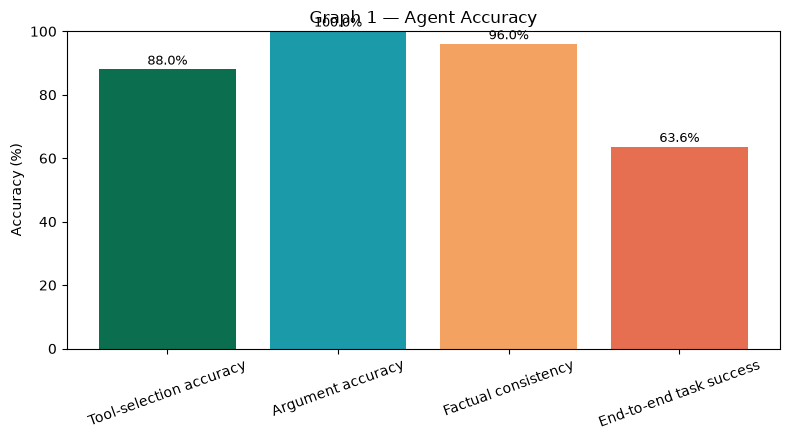

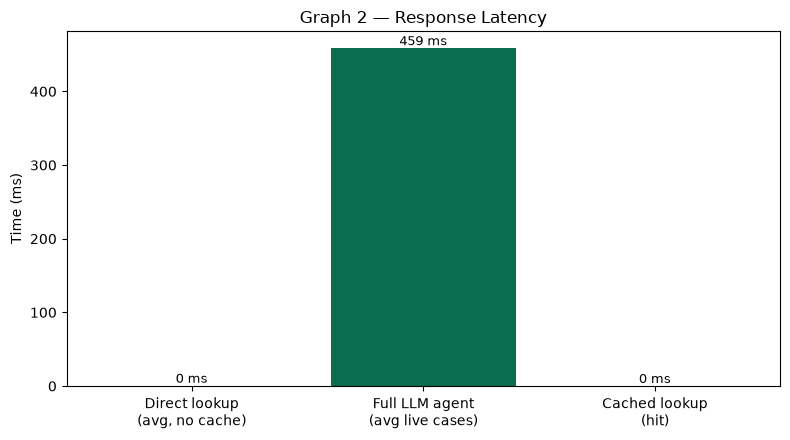

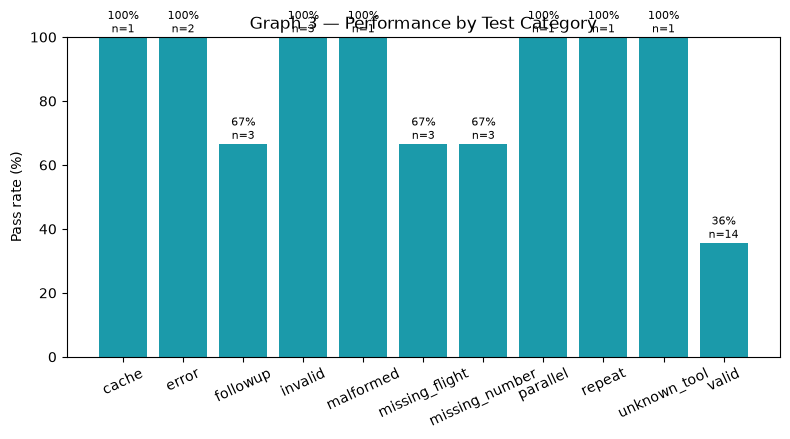

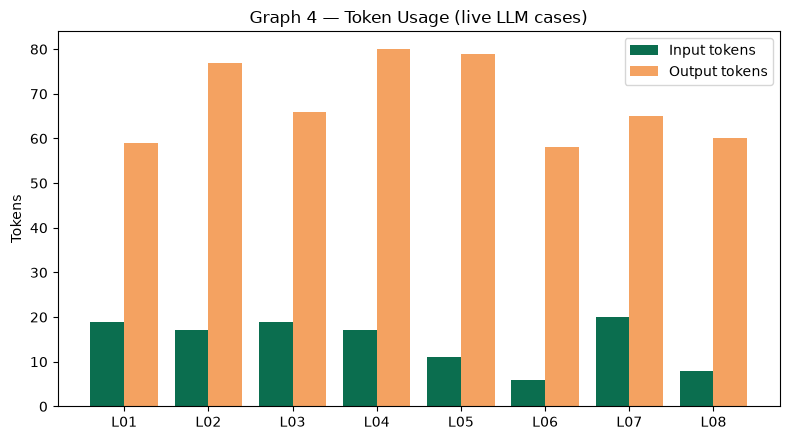

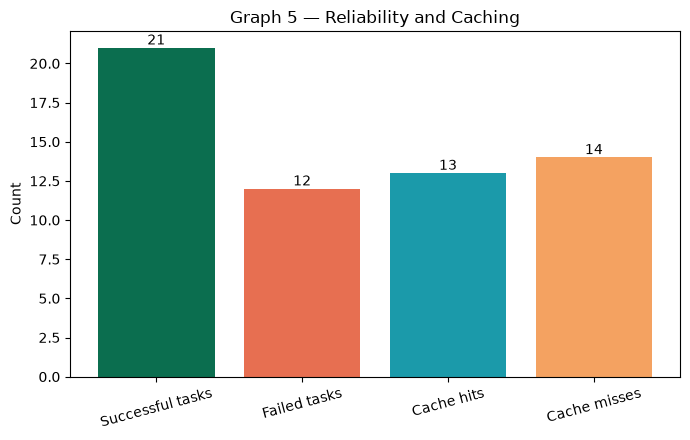


Compact evaluation summary
                 metric  value
Tool-selection accuracy  88.0%
      Argument accuracy 100.0%
    Factual consistency  96.0%
End-to-end task success  63.6%
  Safe failure handling 100.0%
       Latency mean (s)  0.248
     Latency median (s)  0.000
        Latency P95 (s)  0.961
             Cache hits     13
           Cache misses     14
             Eval cases     33


In [14]:
# Metric summary from actual results
def pct(series):
    s = series.dropna()
    return 100.0 * float(s.mean()) if len(s) else 0.0

summary = {
    "Tool-selection accuracy": pct(eval_df["tool_selection_ok"]),
    "Argument accuracy": pct(eval_df["argument_ok"]),
    "Factual consistency": pct(eval_df["factual_ok"]),
    "End-to-end task success": pct(eval_df["task_success"]),
    "Safe failure handling": pct(eval_df["safe_failure"]),
}
print("Evaluation summary (%):")
for k, v in summary.items():
    print(f"  {k}: {v:.1f}")

lat = eval_df["latency_s"].dropna()
print(f"Latency seconds — mean={lat.mean():.3f}, median={lat.median():.3f}, p95={lat.quantile(0.95):.3f}")

# Graph 1 — Agent Accuracy
palette = ["#0B6E4F", "#1B9AAA", "#F4A261", "#E76F51"]
fig, ax = plt.subplots(figsize=(8, 4.5))
names = list(summary.keys())[:4]
vals = [summary[n] for n in names]
bars = ax.bar(names, vals, color=palette)
ax.set_ylim(0, 100)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Graph 1 — Agent Accuracy")
ax.tick_params(axis="x", rotation=20)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 1.5, f"{v:.1f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

# Graph 2 — Response Latency
lookup_times = []
for _ in range(3):
    t0 = time.perf_counter(); get_flight_info(sample_number, sample_date, use_cache=False); lookup_times.append((time.perf_counter()-t0)*1000)
lookup_cache.clear()
t0 = time.perf_counter(); get_flight_info(sample_number, sample_date, use_cache=True); miss_ms = (time.perf_counter()-t0)*1000
t0 = time.perf_counter(); get_flight_info(sample_number, sample_date, use_cache=True); hit_ms = (time.perf_counter()-t0)*1000
agent_ms = eval_df.loc[eval_df["source"] == "live", "latency_s"].dropna() * 1000
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["Direct lookup\n(avg, no cache)", "Full LLM agent\n(avg live cases)", "Cached lookup\n(hit)"]
values = [
    sum(lookup_times)/len(lookup_times),
    float(agent_ms.mean()) if len(agent_ms) else 0.0,
    hit_ms,
]
bars = ax.bar(labels, values, color=["#1B9AAA", "#0B6E4F", "#F4A261"])
ax.set_ylabel("Time (ms)")
ax.set_title("Graph 2 — Response Latency")
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:.0f} ms", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

# Graph 3 — Pass rate by category
cat = eval_df.groupby("category").agg(pass_rate=("task_success", "mean"), n=("task_success", "size")).reset_index()
cat["pass_rate"] = cat["pass_rate"] * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(cat["category"], cat["pass_rate"], color="#1B9AAA")
ax.set_ylim(0, 100)
ax.set_ylabel("Pass rate (%)")
ax.set_title("Graph 3 — Performance by Test Category")
ax.tick_params(axis="x", rotation=25)
for b, v, n in zip(bars, cat["pass_rate"], cat["n"]):
    ax.text(b.get_x() + b.get_width()/2, v + 1.5, f"{v:.0f}%\nn={n}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

# Graph 4 — Token usage for live LLM questions
tok = eval_df.loc[eval_df["source"] == "live", ["id", "input_tokens", "output_tokens"]].dropna()
if len(tok):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x = range(len(tok))
    ax.bar([i - 0.2 for i in x], tok["input_tokens"], width=0.4, label="Input tokens", color="#0B6E4F")
    ax.bar([i + 0.2 for i in x], tok["output_tokens"], width=0.4, label="Output tokens", color="#F4A261")
    ax.set_xticks(list(x))
    ax.set_xticklabels(tok["id"].tolist())
    ax.set_ylabel("Tokens")
    ax.set_title("Graph 4 — Token Usage (live LLM cases)")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No live token rows to plot.")

# Graph 5 — Reliability and caching
fig, ax = plt.subplots(figsize=(7, 4.5))
reliab = [
    int(eval_df["task_success"].sum()),
    int((~eval_df["task_success"].fillna(False)).sum()),
    int(cache_hits),
    int(cache_misses),
]
labels = ["Successful tasks", "Failed tasks", "Cache hits", "Cache misses"]
bars = ax.bar(labels, reliab, color=["#0B6E4F", "#E76F51", "#1B9AAA", "#F4A261"])
ax.set_ylabel("Count")
ax.set_title("Graph 5 — Reliability and Caching")
ax.tick_params(axis="x", rotation=15)
for b, v in zip(bars, reliab):
    ax.text(b.get_x() + b.get_width()/2, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

summary_table = pd.DataFrame([
    {"metric": k, "value": f"{v:.1f}%"} for k, v in summary.items()
] + [
    {"metric": "Latency mean (s)", "value": f"{lat.mean():.3f}"},
    {"metric": "Latency median (s)", "value": f"{lat.median():.3f}"},
    {"metric": "Latency P95 (s)", "value": f"{lat.quantile(0.95):.3f}"},
    {"metric": "Cache hits", "value": str(cache_hits)},
    {"metric": "Cache misses", "value": str(cache_misses)},
    {"metric": "Eval cases", "value": str(len(eval_df))},
])
print("\nCompact evaluation summary")
print(summary_table.to_string(index=False))

## 15. Three quick integration demos

Smoke checks for found / not found / missing flight number.

ملاحظة: تم تطبيق مفهوم اختبار تكامل الأدوات (Integration Testing) من المعمل الثالث (Lab 3).

In [15]:
demos = [
    ("Found", f"What is the status of flight {sample_number}" + (f" on {sample_date}" if sample_date else "") + "?"),
    ("Not found", "Where is flight ZZ9999 on 2099-01-01?"),
    ("Missing number", "What gate should I go to for my flight?"),
]
for title, q in demos:
    out = ask(q, mem=Memory())
    print("=" * 60)
    print(title, "|", q)
    print("used_tool:", out["used_tool"], "| tool_call:", out.get("tool_call"))
    if out.get("retrieved"):
        print("found:", out["retrieved"].get("found"), "|", out["retrieved"].get("message"))
    print("final:", out["final"])

Found | What is the status of flight XY790 on 2026-11-12?
used_tool: True | tool_call: {'name': 'get_flight_info', 'arguments': {'flight_number': 'XY790', 'flight_date': '2026-11-12'}}
found: True | Found 1 matching flight(s).
final: Flight status is currently unavailable.


Not found | Where is flight ZZ9999 on 2099-01-01?
used_tool: True | tool_call: {'name': 'get_flight_info', 'arguments': {'flight_number': 'ZZ9999', 'flight_date': '2099-01-01'}}
found: False | This flight is unavailable in the current airport feed.
final: This flight is unavailable in the current airport feed.


Missing number | What gate should I go to for my flight?
used_tool: False | tool_call: None
final: I'm sorry, but I don't have access to the specific gate assignment for your flight. To find out which gate you should head to, please check the latest gate information provided by the airline or use the airport's mobile app/website. If you have the flight number, let me know and I can help you look up other details like the terminal or scheduled departure time.


## Conclusion

Aviation AI is a smart airport assistant that retrieves live KKIA flight information and answers passenger questions with LiquidAI LFM2.5 tool calling.

**Lab concepts applied:** Lab 1 tokenization/cost awareness; Lab 2 retry, caching, streaming, TTFT; Lab 3 schema/validation/registry/parallel tools; Lab 6 conversation memory and fidelity gate; Lab 7 max steps, loop detection, tracing, and evaluation.

**Key evaluation takeaway:** See the dashboard summary table above for measured accuracies, latency, token usage, and cache behavior from this run. Scores are computed from actual notebook results, not invented.

**Strengths:** Real airport JSON retrieval; clear separation of missing flight fields vs API failures; validated tool arguments; grounded answers; educational lab coverage.

**Limitations:** The 1.2B model can still mis-handle edge prompts; flight boards change over time; short-lived cache may serve slightly stale values within the TTL; parallel speedups were demonstrated with a labeled simulated delay when lookups are in-memory.

**Future improvements:** Broader multi-tool support, stronger follow-up understanding, richer status-code explanations from official labels only, and a user interface (not built in this phase).